<a href="https://colab.research.google.com/github/HARISHRAJ-R-07/Crowdfunding-Campaign-Classification-model-building-and-hyper-parameter-tuning/blob/main/Assignment_07_Classification_Algorithms_Model_Building.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Module - 4**
#**⌨ Assignment 07: Classification Algorithms Model Building**

##**Project Title: Crowdfunding Campaign Success Prediction**



> * Crowdfunding platforms host thousands of campaigns across categories such as technology,
education, healthcare, and creative arts. However, not all campaigns achieve their funding goals.
Businesses and investors want to understand which campaign factors influence success and which
machine learning model can best predict campaign outcomes.

> * In this project, you will build and compare multiple classification models to predict whether a
crowdfunding campaign will be Successful or Unsuccessful based on campaign-related features such
as funding goal, campaign duration, backer engagement, and pledged amount.

> * The project focuses on model evaluation, cross-validation, hyperparameter tuning, and selecting the
best-performing classification model.

In [ ]:
# Import the dataset to analyze

import numpy as np
import pandas as pd

data = pd.read_csv("https://raw.githubusercontent.com/GeethaGunasekaran1/Dataset_rep/refs/heads/main/crowdfunding.csv")

##**Task 1 – Data Exploration & Preprocessing**



> ● **Load and inspect the dataset**

> ● **Handle missing values and duplicates**

> ● **Encode categorical variables**

> ● **Perform feature selection**

> ● **Split the dataset into training and testing sets**

> ● **Apply feature scaling where required**







> ● **Load and inspect the dataset**

In [ ]:
# Load and inspect the dataset

data.head(7)

,Unnamed: 0,CampaignID,GoalAmount,RaisedAmount,DurationDays,NumBackers,Category,LaunchMonth,Country,Currency,OwnerExperience,VideoIncluded,SocialMediaPresence,NumUpdates,IsSuccessful
0,0,CID_00000,76159,73518.028955,15,1903,Film,September,Australia,GBP,11,Yes,41758,3,0
1,1,CID_00001,69394,60068.683288,49,469,Art,October,Australia,GBP,7,Yes,79112,48,0
2,2,CID_00002,18652,22958.153470,58,148,Film,February,USA,EUR,17,No,3942,9,1
3,3,CID_00003,19487,24229.048390,39,780,Film,October,Germany,AUD,10,No,22047,35,1
4,4,CID_00004,26734,17984.630311,68,1622,Games,September,Australia,AUD,12,Yes,72568,17,0
5,5,CID_00005,33621,26373.541145,88,819,Film,April,USA,EUR,8,No,73736,25,0
6,6,CID_00006,77380,59282.025167,47,1214,Art,June,UK,CAD,14,Yes,24899,42,0


> ● **Handle missing values and duplicates**

In [ ]:
# drop unwanted column : Unnamed: 0

data.drop(['Unnamed: 0'],axis=1,inplace=True)
data.isnull().sum()

,0
CampaignID,0
GoalAmount,0
RaisedAmount,0
DurationDays,0
NumBackers,0
Category,0
LaunchMonth,0
Country,0
Currency,0
OwnerExperience,0


In [ ]:
data['RaisedAmount'] = data['RaisedAmount'].astype(int)

In [ ]:
data.head()

,CampaignID,GoalAmount,RaisedAmount,DurationDays,NumBackers,Category,LaunchMonth,Country,Currency,OwnerExperience,VideoIncluded,SocialMediaPresence,NumUpdates,IsSuccessful
0,CID_00000,76159,73518,15,1903,Film,September,Australia,GBP,11,Yes,41758,3,0
1,CID_00001,69394,60068,49,469,Art,October,Australia,GBP,7,Yes,79112,48,0
2,CID_00002,18652,22958,58,148,Film,February,USA,EUR,17,No,3942,9,1
3,CID_00003,19487,24229,39,780,Film,October,Germany,AUD,10,No,22047,35,1
4,CID_00004,26734,17984,68,1622,Games,September,Australia,AUD,12,Yes,72568,17,0


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 14 columns):
 #   Column               Non-Null Count   Dtype 
---  ------               --------------   ----- 
 0   CampaignID           100000 non-null  object
 1   GoalAmount           100000 non-null  int64 
 2   RaisedAmount         100000 non-null  int64 
 3   DurationDays         100000 non-null  int64 
 4   NumBackers           100000 non-null  int64 
 5   Category             100000 non-null  object
 6   LaunchMonth          100000 non-null  object
 7   Country              100000 non-null  object
 8   Currency             100000 non-null  object
 9   OwnerExperience      100000 non-null  int64 
 10  VideoIncluded        100000 non-null  object
 11  SocialMediaPresence  100000 non-null  int64 
 12  NumUpdates           100000 non-null  int64 
 13  IsSuccessful         100000 non-null  int64 
dtypes: int64(8), object(6)
memory usage: 10.7+ MB


In [ ]:
print("Category:",data['Category'].unique())
print("Launchmonth:",data['LaunchMonth'].unique())
print("Country:",data['Country'].unique())
print("Currency:",data['Currency'].unique())
print("Video Included:",data['VideoIncluded'].unique())

Category: ['Film' 'Art' 'Games' 'Music' 'Technology']
Launchmonth: ['September' 'October' 'February' 'April' 'June' 'July' 'March' 'January'
 'August' 'December' 'November' 'May']
Country: ['Australia' 'USA' 'Germany' 'UK' 'Canada']
Currency: ['GBP' 'EUR' 'AUD' 'CAD' 'USD']
Video Included: ['Yes' 'No']


In [ ]:
df = data
df.drop(['CampaignID'],axis=1,inplace=True)
df

,GoalAmount,RaisedAmount,DurationDays,NumBackers,Category,LaunchMonth,Country,Currency,OwnerExperience,VideoIncluded,SocialMediaPresence,NumUpdates,IsSuccessful
0,76159,73518,15,1903,Film,September,Australia,GBP,11,Yes,41758,3,0
1,69394,60068,49,469,Art,October,Australia,GBP,7,Yes,79112,48,0
2,18652,22958,58,148,Film,February,USA,EUR,17,No,3942,9,1
3,19487,24229,39,780,Film,October,Germany,AUD,10,No,22047,35,1
4,26734,17984,68,1622,Games,September,Australia,AUD,12,Yes,72568,17,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,80417,112068,26,870,Music,October,UK,AUD,6,No,84173,8,1
99996,85052,100430,78,1146,Film,October,USA,USD,8,No,13913,42,1
99997,68407,102020,87,636,Art,March,UK,EUR,2,Yes,45273,13,1
99998,59749,67026,51,1276,Music,August,Australia,CAD,10,Yes,67574,29,1


In [ ]:
categorical_col = df.select_dtypes(include=object)

> ● **Encode categorical variables**


In [ ]:
# labelencoding for VideoIncluded column

from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['VideoIncluded'] = le.fit_transform(df['VideoIncluded'])
print("classes in this column:",list(le.classes_))
df.head(3)

classes in this column: ['No', 'Yes']


,GoalAmount,RaisedAmount,DurationDays,NumBackers,Category,LaunchMonth,Country,Currency,OwnerExperience,VideoIncluded,SocialMediaPresence,NumUpdates,IsSuccessful
0,76159,73518,15,1903,Film,September,Australia,GBP,11,1,41758,3,0
1,69394,60068,49,469,Art,October,Australia,GBP,7,1,79112,48,0
2,18652,22958,58,148,Film,February,USA,EUR,17,0,3942,9,1


In [ ]:
# One-hot encode multiple columns
df_sam = pd.get_dummies(df, columns=["Category","LaunchMonth","Country","Currency"], drop_first=True).astype(int)
df_sam

,GoalAmount,RaisedAmount,DurationDays,NumBackers,OwnerExperience,VideoIncluded,SocialMediaPresence,NumUpdates,IsSuccessful,Category_Film,...,LaunchMonth_October,LaunchMonth_September,Country_Canada,Country_Germany,Country_UK,Country_USA,Currency_CAD,Currency_EUR,Currency_GBP,Currency_USD
0,76159,73518,15,1903,11,1,41758,3,0,1,...,0,1,0,0,0,0,0,0,1,0
1,69394,60068,49,469,7,1,79112,48,0,0,...,1,0,0,0,0,0,0,0,1,0
2,18652,22958,58,148,17,0,3942,9,1,1,...,0,0,0,0,0,1,0,1,0,0
3,19487,24229,39,780,10,0,22047,35,1,1,...,1,0,0,1,0,0,0,0,0,0
4,26734,17984,68,1622,12,1,72568,17,0,0,...,0,1,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,80417,112068,26,870,6,0,84173,8,1,0,...,1,0,0,0,1,0,0,0,0,0
99996,85052,100430,78,1146,8,0,13913,42,1,1,...,1,0,0,0,0,1,0,0,0,1
99997,68407,102020,87,636,2,1,45273,13,1,0,...,0,0,0,0,1,0,0,1,0,0
99998,59749,67026,51,1276,10,1,67574,29,1,0,...,0,0,0,0,0,0,1,0,0,0



> ● **Perform feature selection**

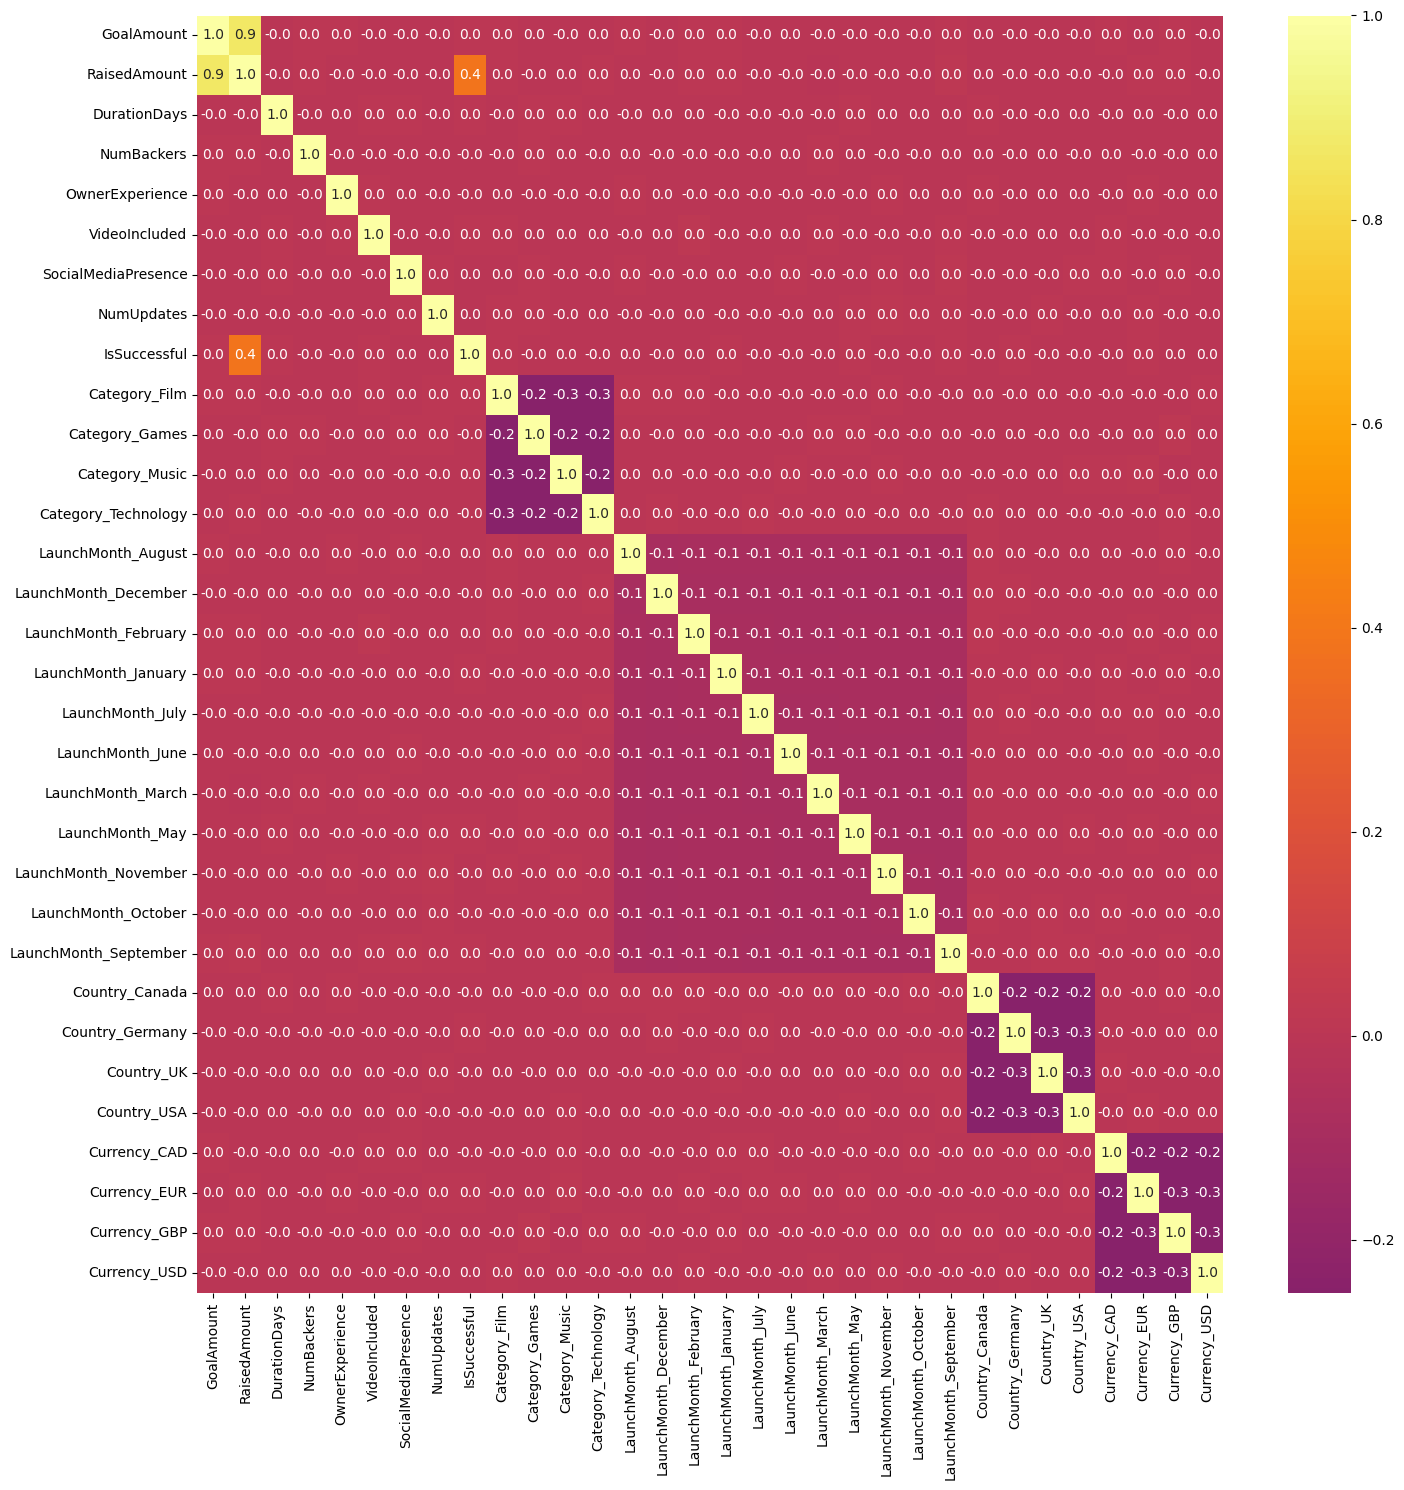

In [ ]:
# Perform feature selection(correlation)

corr = df_sam.corr()

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15,15))
sns.heatmap(corr, annot=True, fmt=".1f", cmap="inferno", center=0)
plt.tight_layout()
plt.show()

In [ ]:
# feature selection by the SelectKBest

from sklearn.feature_selection import SelectKBest, f_classif

selector=SelectKBest(score_func=f_classif,k=17)
best_features=selector.fit_transform(df_sam,df_sam['IsSuccessful'])
selected_features=df_sam.columns[selector.get_support()]

print("Selected features:", list(selected_features))

Selected features: ['GoalAmount', 'RaisedAmount', 'DurationDays', 'NumBackers', 'OwnerExperience', 'VideoIncluded', 'IsSuccessful', 'LaunchMonth_December', 'LaunchMonth_January', 'LaunchMonth_July', 'LaunchMonth_March', 'LaunchMonth_May', 'LaunchMonth_October', 'LaunchMonth_September', 'Country_Germany', 'Currency_CAD', 'Currency_EUR']


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: divide by zero encountered in divide
  f = msb / msw


In [ ]:
x = df_sam[['GoalAmount', 'RaisedAmount', 'DurationDays', 'NumBackers', 'OwnerExperience', 'VideoIncluded' , 'LaunchMonth_December', 'LaunchMonth_January', 'LaunchMonth_July', 'LaunchMonth_March', 'LaunchMonth_May', 'LaunchMonth_October', 'LaunchMonth_September', 'Country_Germany', 'Currency_CAD', 'Currency_EUR']]
y = df_sam['IsSuccessful']


In [ ]:
x.head(3)

,GoalAmount,RaisedAmount,DurationDays,NumBackers,OwnerExperience,VideoIncluded,LaunchMonth_December,LaunchMonth_January,LaunchMonth_July,LaunchMonth_March,LaunchMonth_May,LaunchMonth_October,LaunchMonth_September,Country_Germany,Currency_CAD,Currency_EUR
0,76159,73518,15,1903,11,1,0,0,0,0,0,0,1,0,0,0
1,69394,60068,49,469,7,1,0,0,0,0,0,1,0,0,0,0
2,18652,22958,58,148,17,0,0,0,0,0,0,0,0,0,0,1


In [ ]:
y.head(3)

,IsSuccessful
0,0
1,0
2,1



> ● **Split the dataset into training and testing sets**

In [ ]:
# Split the dataset into training and testing sets

from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test = train_test_split(x ,y ,test_size=0.25,random_state=42)

In [ ]:
print(len(x_train),len(x_test))

75000 25000


In [ ]:
x_train

,GoalAmount,RaisedAmount,DurationDays,NumBackers,OwnerExperience,VideoIncluded,LaunchMonth_December,LaunchMonth_January,LaunchMonth_July,LaunchMonth_March,LaunchMonth_May,LaunchMonth_October,LaunchMonth_September,Country_Germany,Currency_CAD,Currency_EUR
98980,15607,17119,33,1516,15,0,1,0,0,0,0,0,0,0,1,0
69824,11209,14007,72,1919,9,0,0,0,0,1,0,0,0,0,0,1
9928,50681,38746,59,762,0,0,0,0,0,1,0,0,0,0,0,0
75599,27559,16034,40,448,15,1,1,0,0,0,0,0,0,0,0,1
95621,3446,2757,85,459,16,1,0,0,0,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6265,93941,84408,65,1549,9,1,0,0,0,0,0,1,0,1,1,0
54886,6813,5575,75,1823,6,1,0,0,0,0,0,0,0,1,0,1
76820,72731,100753,19,345,8,1,0,0,0,0,0,0,0,0,0,0
860,23186,16920,34,195,7,0,0,0,0,0,0,1,0,0,0,1


In [ ]:
x_test

,GoalAmount,RaisedAmount,DurationDays,NumBackers,OwnerExperience,VideoIncluded,LaunchMonth_December,LaunchMonth_January,LaunchMonth_July,LaunchMonth_March,LaunchMonth_May,LaunchMonth_October,LaunchMonth_September,Country_Germany,Currency_CAD,Currency_EUR
75721,61012,36911,43,1263,17,1,0,0,0,0,0,0,0,0,0,1
80184,11237,8758,83,1962,17,0,0,0,0,0,0,0,1,0,0,1
19864,12917,13702,61,373,0,0,0,0,0,1,0,0,0,0,0,0
76699,64025,49952,61,418,2,0,0,0,0,0,1,0,0,0,1,0
92991,74814,57301,63,854,2,0,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21271,12322,12406,58,25,5,1,0,0,0,1,0,0,0,0,0,0
34014,37146,37114,54,1501,7,1,0,0,0,0,0,0,1,0,0,0
81355,71284,56254,15,107,14,0,0,0,1,0,0,0,0,0,0,0
65720,5091,5966,19,399,4,0,0,1,0,0,0,0,0,1,0,0


In [ ]:
y_train

,IsSuccessful
98980,1
69824,1
9928,0
75599,0
95621,0
...,...
6265,0
54886,0
76820,1
860,0


In [ ]:
y_test

,IsSuccessful
75721,0
80184,0
19864,1
76699,0
92991,0
...,...
21271,1
34014,0
81355,0
65720,1


In [ ]:
x_train.describe()

,GoalAmount,RaisedAmount,DurationDays,NumBackers,OwnerExperience,VideoIncluded,LaunchMonth_December,LaunchMonth_January,LaunchMonth_July,LaunchMonth_March,LaunchMonth_May,LaunchMonth_October,LaunchMonth_September,Country_Germany,Currency_CAD,Currency_EUR
count,75000.000000,75000.000000,75000.000000,75000.000000,75000.000000,75000.000000,75000.000000,75000.000000,75000.000000,75000.000000,75000.000000,75000.00000,75000.000000,75000.00000,75000.000000,75000.000000
mean,50565.557853,50616.720813,51.999413,1005.001253,9.487360,0.498640,0.085107,0.081173,0.082427,0.084253,0.083867,0.08400,0.084013,0.20112,0.199280,0.201027
std,28611.587781,33255.678799,21.633949,574.205359,5.761638,0.500001,0.279042,0.273103,0.275015,0.277769,0.277190,0.27739,0.277410,0.40084,0.399462,0.400771
min,1000.000000,528.000000,15.000000,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,0.000000
25%,25670.750000,23388.750000,33.000000,508.000000,4.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,0.000000
50%,50776.500000,46148.000000,52.000000,1005.000000,9.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,0.000000
75%,75347.250000,72771.000000,71.000000,1503.000000,14.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,0.000000
max,99999.000000,149238.000000,89.000000,1999.000000,19.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000,1.000000,1.00000,1.000000,1.000000


In [ ]:
x_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 75000 entries, 98980 to 15795
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   GoalAmount             75000 non-null  int64
 1   RaisedAmount           75000 non-null  int64
 2   DurationDays           75000 non-null  int64
 3   NumBackers             75000 non-null  int64
 4   OwnerExperience        75000 non-null  int64
 5   VideoIncluded          75000 non-null  int64
 6   LaunchMonth_December   75000 non-null  int64
 7   LaunchMonth_January    75000 non-null  int64
 8   LaunchMonth_July       75000 non-null  int64
 9   LaunchMonth_March      75000 non-null  int64
 10  LaunchMonth_May        75000 non-null  int64
 11  LaunchMonth_October    75000 non-null  int64
 12  LaunchMonth_September  75000 non-null  int64
 13  Country_Germany        75000 non-null  int64
 14  Currency_CAD           75000 non-null  int64
 15  Currency_EUR           75000 non-null

In [ ]:
x_train_index = x_train.columns
print(x_train_index)
x_test_index = x_test.columns

Index(['GoalAmount', 'RaisedAmount', 'DurationDays', 'NumBackers',
       'OwnerExperience', 'VideoIncluded', 'LaunchMonth_December',
       'LaunchMonth_January', 'LaunchMonth_July', 'LaunchMonth_March',
       'LaunchMonth_May', 'LaunchMonth_October', 'LaunchMonth_September',
       'Country_Germany', 'Currency_CAD', 'Currency_EUR'],
      dtype='object')


> **● Apply feature scaling where required**

In [ ]:
# Feature scaling by StandardScaler

from IPython.display import display
from sklearn.preprocessing import StandardScaler, MinMaxScaler

scaler_standard = StandardScaler()

col_to_scale = ['GoalAmount', 'RaisedAmount', 'DurationDays', 'NumBackers']

x_train[col_to_scale] = scaler_standard.fit_transform(x_train[col_to_scale])
x_test[col_to_scale] = scaler_standard.transform(x_test[col_to_scale])

display("X_train:",
        x_train.describe().round(3))
display("X_test:",
        x_test.describe().round(3))

'X_train:'

,GoalAmount,RaisedAmount,DurationDays,NumBackers,OwnerExperience,VideoIncluded,LaunchMonth_December,LaunchMonth_January,LaunchMonth_July,LaunchMonth_March,LaunchMonth_May,LaunchMonth_October,LaunchMonth_September,Country_Germany,Currency_CAD,Currency_EUR
count,75000.000,75000.000,75000.000,75000.000,75000.000,75000.000,75000.000,75000.000,75000.000,75000.000,75000.000,75000.000,75000.000,75000.000,75000.000,75000.000
mean,0.000,-0.000,-0.000,-0.000,9.487,0.499,0.085,0.081,0.082,0.084,0.084,0.084,0.084,0.201,0.199,0.201
std,1.000,1.000,1.000,1.000,5.762,0.500,0.279,0.273,0.275,0.278,0.277,0.277,0.277,0.401,0.399,0.401
min,-1.732,-1.506,-1.710,-1.733,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,-0.870,-0.819,-0.878,-0.866,4.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
50%,0.007,-0.134,0.000,-0.000,9.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
75%,0.866,0.666,0.878,0.867,14.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
max,1.728,2.966,1.710,1.731,19.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000


'X_test:'

,GoalAmount,RaisedAmount,DurationDays,NumBackers,OwnerExperience,VideoIncluded,LaunchMonth_December,LaunchMonth_January,LaunchMonth_July,LaunchMonth_March,LaunchMonth_May,LaunchMonth_October,LaunchMonth_September,Country_Germany,Currency_CAD,Currency_EUR
count,25000.000,25000.000,25000.000,25000.000,25000.000,25000.000,25000.000,25000.000,25000.000,25000.000,25000.000,25000.000,25000.000,25000.000,25000.000,25000.0
mean,-0.004,-0.002,0.009,-0.012,9.494,0.497,0.084,0.084,0.084,0.084,0.082,0.080,0.082,0.205,0.194,0.2
std,1.000,1.000,1.004,1.002,5.769,0.500,0.278,0.277,0.277,0.277,0.275,0.272,0.275,0.403,0.395,0.4
min,-1.732,-1.505,-1.710,-1.733,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0
25%,-0.862,-0.818,-0.878,-0.885,4.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0
50%,-0.001,-0.155,0.000,-0.017,9.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0
75%,0.861,0.668,0.878,0.857,15.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0
max,1.728,2.946,1.710,1.731,19.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.0


##**Task 2 – Classification Model Building**
>**Build and train the following classification models:**

>**● Random Forest Classifier**

>**● KNN**

>**● Decision Tree**

>**● Naive Bayes Classifier**

>**● Support Vector Machine (SVM)**

>**Experiment with different model parameters to improve performance.**

#`● Random Forest Classifier`

In [ ]:
# Build and train the following classification models

# ● Random Forest Classifier:

from sklearn.ensemble import RandomForestClassifier
rf_classifier=RandomForestClassifier(n_estimators=100,random_state=42)

# fit() the model

rf_classifier.fit(x_train,y_train)

RandomForestClassifier(random_state=42)

In [ ]:
# make prediction

rf_y_pred=rf_classifier.predict(x_test)

rf_classifier.score(x_train,y_train)

1.0

#`● KNN`

In [ ]:
# ● KNN

from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=7)

# fit() the model

knn.fit(x_train,y_train)


KNeighborsClassifier(n_neighbors=7)

In [ ]:
# make prediction

knn_y_pred = knn.predict(x_test)

knn.score(x_train,y_train)

0.8444933333333333

#`● Decision Tree`

In [ ]:
# ● Decision Tree Classifier

from sklearn.tree import DecisionTreeClassifier
dtc_classifier = DecisionTreeClassifier(criterion='gini', max_depth=7, random_state=42)

# fit() the model

dtc_classifier.fit(x_train,y_train)


DecisionTreeClassifier(max_depth=7, random_state=42)

In [ ]:
# make predictions

dtc_y_pred = dtc_classifier.predict(x_test)

dtc_classifier.score(x_train,y_train)

0.8942266666666666

#`● Naive Bayes Classifier`



In [ ]:
# ● Naive Bayes Classifier

from sklearn.naive_bayes import GaussianNB
nb_classifier = GaussianNB()

# fit() the model

nb_classifier.fit(x_train,y_train)

GaussianNB()

In [ ]:
# make predictions

nb_y_pred = nb_classifier.predict(x_test)

nb_classifier.score(x_train,y_train)

0.66308

#`● Support Vector Machine (SVM)`

In [ ]:
# ● Support Vector Machine (SVM)

from sklearn.svm import SVC
svm_classifier = SVC(kernel="linear",gamma="scale",C=0.1)

# fit() the model

svm_classifier.fit(x_train,y_train)

SVC(C=0.1, kernel='linear')

In [ ]:
# make predictions

svm_y_pred = svm_classifier.predict(x_test)

svm_classifier.score(x_train,y_train)

0.9968266666666666

##**Task 3 – Model Evaluation**

**Evaluate all models using:**

>**● Accuracy**

>**● Precision**

>**● Recall**

>**● F1-Score**

>**● Confusion Matrix**

>**Compare training and testing performance.**

In [ ]:
# import evaluation metrics

from sklearn.metrics import accuracy_score, recall_score, f1_score, confusion_matrix, classification_report, precision_score

##`● Random Forest Classifier Evaluation`

In [ ]:
# Evaluate the Randonforestclassifier model

print(f"Accuracy Score: {accuracy_score(y_test,rf_y_pred)}")
print(f"Precision Score: {precision_score(y_test,rf_y_pred)}")
print(f"Recall Score: {recall_score(y_test,rf_y_pred)}" )
print(f"F1 Score {f1_score(y_test,rf_y_pred)}")
print(f"Confusion Matrix:\n\n {confusion_matrix(y_test,rf_y_pred)}")

Accuracy Score: 0.97604
Precision Score: 0.9860805860805861
Recall Score: 0.9658746611385743
F1 Score 0.975873041446812
Confusion Matrix:

 [[12287   171]
 [  428 12114]]


In [ ]:
# Classification Report

print(f"Classification Report: \n\n {classification_report(y_test,rf_y_pred)}")

Classification Report: 

               precision    recall  f1-score   support

           0       0.97      0.99      0.98     12458
           1       0.99      0.97      0.98     12542

    accuracy                           0.98     25000
   macro avg       0.98      0.98      0.98     25000
weighted avg       0.98      0.98      0.98     25000



##`● KNN Evaluation`

In [ ]:
# Evaluate the KNN model

print(f"Accuracy Score: {accuracy_score(y_test,knn_y_pred)}")
print(f"Precision Score: {precision_score(y_test,knn_y_pred)}")
print(f"Recall Score: {recall_score(y_test,knn_y_pred)}" )
print(f"F1 Score {f1_score(y_test,knn_y_pred)}")
print(f"Confusion Matrix:\n\n {confusion_matrix(y_test,knn_y_pred)}")

Accuracy Score: 0.76444
Precision Score: 0.7758978186945343
Recall Score: 0.7458937968426088
F1 Score 0.7606000243912354
Confusion Matrix:

 [[9756 2702]
 [3187 9355]]


In [ ]:
# Classification Report

print(f"Classification Report: \n\n {classification_report(y_test,knn_y_pred)}")

Classification Report: 

               precision    recall  f1-score   support

           0       0.75      0.78      0.77     12458
           1       0.78      0.75      0.76     12542

    accuracy                           0.76     25000
   macro avg       0.76      0.76      0.76     25000
weighted avg       0.76      0.76      0.76     25000



##`● Decision Tree Evaluation`

In [ ]:
# Evaluate the Decision Tree model

print(f"Accuracy Score: {accuracy_score(y_test,dtc_y_pred)}")
print(f"Precision Score: {precision_score(y_test,dtc_y_pred)}")
print(f"Recall Score: {recall_score(y_test,dtc_y_pred)}" )
print(f"F1 Score {f1_score(y_test,dtc_y_pred)}")
print(f"Confusion Matrix:\n\n {confusion_matrix(y_test,dtc_y_pred)}")

Accuracy Score: 0.88764
Precision Score: 0.9565625293179473
Recall Score: 0.8129484930633073
F1 Score 0.8789276324296367
Confusion Matrix:

 [[11995   463]
 [ 2346 10196]]


In [ ]:
y_test.value_counts()

,count
IsSuccessful,
1,12542
0,12458


In [ ]:
# Classification Report

print(f"Classification Report: \n\n {classification_report(y_test,dtc_y_pred)}")

Classification Report: 

               precision    recall  f1-score   support

           0       0.84      0.96      0.90     12458
           1       0.96      0.81      0.88     12542

    accuracy                           0.89     25000
   macro avg       0.90      0.89      0.89     25000
weighted avg       0.90      0.89      0.89     25000



##`● Naive Bayes Classifier Evaluation`



In [ ]:
# Evaluate the Naive Bayes Classifier model

print(f"Accuracy Score: {accuracy_score(y_test,nb_y_pred)}")
print(f"Precision Score: {precision_score(y_test,nb_y_pred)}")
print(f"Recall Score: {recall_score(y_test,nb_y_pred)}" )
print(f"F1 Score {f1_score(y_test,nb_y_pred)}")
print(f"Confusion Matrix:\n\n {confusion_matrix(y_test,nb_y_pred)}")

Accuracy Score: 0.662
Precision Score: 0.7281954048628151
Recall Score: 0.5205708818370276
F1 Score 0.6071229310024177
Confusion Matrix:

 [[10021  2437]
 [ 6013  6529]]


In [ ]:
# Classification Report

print(f"Classification Report: \n\n {classification_report(y_test,nb_y_pred)}")

Classification Report: 

               precision    recall  f1-score   support

           0       0.62      0.80      0.70     12458
           1       0.73      0.52      0.61     12542

    accuracy                           0.66     25000
   macro avg       0.68      0.66      0.66     25000
weighted avg       0.68      0.66      0.66     25000



##`● Support Vector Machine (SVM) Evaluation`

In [ ]:
# Evaluate the Support Vector Machine model

print(f"Accuracy Score: {accuracy_score(y_test,svm_y_pred)}")
print(f"Precision Score: {precision_score(y_test,svm_y_pred)}")
print(f"Recall Score: {recall_score(y_test,svm_y_pred)}" )
print(f"F1 Score {f1_score(y_test,svm_y_pred)}")
print(f"Confusion Matrix:\n\n {confusion_matrix(y_test,svm_y_pred)}")

Accuracy Score: 0.99672
Precision Score: 0.9986393468865056
Recall Score: 0.9948174134906713
F1 Score 0.9967247164083719
Confusion Matrix:

 [[12441    17]
 [   65 12477]]


In [ ]:
# Classification Report

print(f"Classification Report: \n\n {classification_report(y_test,svm_y_pred)}")

Classification Report: 

               precision    recall  f1-score   support

           0       0.99      1.00      1.00     12458
           1       1.00      0.99      1.00     12542

    accuracy                           1.00     25000
   macro avg       1.00      1.00      1.00     25000
weighted avg       1.00      1.00      1.00     25000



##**Task 4 – Cross-Validation & Hyperparameter Tuning**

>**● Apply Cross-Validation to evaluate model stability**

>**● Perform Hyperparameter Tuning using GridSearchCV or RandomizedSearchCV**

>**● Identify the best parameters for each model**

>### * **Random Forest Classifier Hyper_parameter tuning**

In [ ]:
# Import needed libraries
from sklearn.model_selection import StratifiedKFold, GridSearchCV, RandomizedSearchCV

In [ ]:
# implement Cross-validation
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

In [ ]:
# parameters
rf_param_dist = {
    'n_estimators': [50, 100, 150],
    'max_depth': [3, 7, 10, None],
    'min_samples_split': [2, 5, 7]
}

In [ ]:
# RandomforestClassifier Hyper_parametertuning

rf_hyper = RandomizedSearchCV(RandomForestClassifier(random_state=42),param_distributions=rf_param_dist,cv=cv,scoring="accuracy",verbose=1,n_jobs=-1)
rf_hyper.fit(x_train,y_train)

Fitting 5 folds for each of 10 candidates, totalling 50 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=RandomForestClassifier(random_state=42), n_jobs=-1,
                   param_distributions={'max_depth': [3, 7, 10, None],
                                        'min_samples_split': [2, 5, 7],
                                        'n_estimators': [50, 100, 150]},
                   scoring='accuracy', verbose=1)

>### * **KNN Hyper_parameter tuning**

In [ ]:
# parameters
knn_param_grid = {
    'n_neighbors': [3, 5, 7, 9],
    'weights': ['uniform', 'distance'],
    'p': [1, 2]
}

In [ ]:
# KNN Hyper_Parametertuning

knn_hyper = GridSearchCV(KNeighborsClassifier(),knn_param_grid,cv=cv,scoring="accuracy",verbose=1,n_jobs=-1)
knn_hyper.fit(x_train,y_train)


Fitting 5 folds for each of 16 candidates, totalling 80 fits


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=KNeighborsClassifier(), n_jobs=-1,
             param_grid={'n_neighbors': [3, 5, 7, 9], 'p': [1, 2],
                         'weights': ['uniform', 'distance']},
             scoring='accuracy', verbose=1)

>### * **Decision tree Classifier Hyper_parameter tuning**

In [ ]:
# parameters

dtc_param_dict = {
    'max_depth': [None, 5, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'criterion': ['gini', 'entropy']
}

In [ ]:
# Decisiontreeclassifier Hyper_parametertuning

dtc_hyper = RandomizedSearchCV(DecisionTreeClassifier(random_state=42),param_distributions=dtc_param_dict,cv=cv,scoring="accuracy",verbose=1,n_jobs=-1)
dtc_hyper.fit(x_train,y_train)

Fitting 5 folds for each of 10 candidates, totalling 50 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=DecisionTreeClassifier(random_state=42), n_jobs=-1,
                   param_distributions={'criterion': ['gini', 'entropy'],
                                        'max_depth': [None, 5, 10, 20],
                                        'min_samples_leaf': [1, 2],
                                        'min_samples_split': [2, 5]},
                   scoring='accuracy', verbose=1)

>### * **Naive bayes(GaussianNB) Hyper_parameter tuning**

In [ ]:
# parameters
nb_param_dist = {
    'var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6]
}

In [ ]:
# Decisiontreeclassifier Hyper_parametertuning

nb_hyper = RandomizedSearchCV(GaussianNB(),param_distributions=nb_param_dist,cv=cv,scoring="accuracy",verbose=1,n_jobs=-1)
nb_hyper.fit(x_train,y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 4 is smaller than n_iter=10. Running 4 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Fitting 5 folds for each of 4 candidates, totalling 20 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=GaussianNB(), n_jobs=-1,
                   param_distributions={'var_smoothing': [1e-09, 1e-08, 1e-07,
                                                          1e-06]},
                   scoring='accuracy', verbose=1)

>### * **Support Vector Classifier(SVM) Hyper_parameter tuning**

In [ ]:
# parameters
svc_param_grid = {
    'C': [0.1, 1],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale']
}

In [ ]:
#  Support Vector Classifier(SVM) Hyper_Parametertuning

svc_hyper = GridSearchCV(SVC(),svc_param_grid,cv=cv,scoring="accuracy",verbose=1,n_jobs=-1)
svc_hyper.fit(x_train,y_train)


Fitting 5 folds for each of 4 candidates, totalling 20 fits


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=SVC(), n_jobs=-1,
             param_grid={'C': [0.1, 1], 'gamma': ['scale'],
                         'kernel': ['linear', 'rbf']},
             scoring='accuracy', verbose=1)

##**Task 5 – Model Comparison & Selection**
>**● Compare all classification models using evaluation metrics**

>**● Identify the best-performing model**

>**● Discuss strengths, weaknesses, and possible improvements**

####`● Compare all classification models using evaluation metrics`

In [ ]:
# Compare all classification models using evaluation metrics

classification_models = {
    'Random Forest Classifier' : (rf_hyper.best_estimator_, x_test),
    'K-Nearest Neighbor' : (knn_hyper.best_estimator_, x_test),
    'Decision Tree Classifier' : (dtc_hyper.best_estimator_, x_test),
    'Naive Bayes(Gaussian) Classifier' : (nb_hyper.best_estimator_, x_test),
    'Support Vector Classifier(SVM)' : (svc_hyper.best_estimator_, x_test)
}

classification_models

{'Random Forest Classifier': (RandomForestClassifier(min_samples_split=7, n_estimators=150, random_state=42),
         GoalAmount  RaisedAmount  DurationDays  NumBackers  OwnerExperience  \
  75721    0.365115     -0.412134     -0.415988    0.449317               17   
  80184   -1.374577     -1.258702      1.432970    1.666660               17   
  19864   -1.315859     -1.110035      0.416043   -1.100661                0   
  76699    0.470422     -0.019988      0.416043   -1.022291                2   
  92991    0.847510      0.200998      0.508491   -0.262976                2   
  ...           ...           ...           ...         ...              ...   
  21271   -1.336655     -1.149006      0.277371   -1.706720                5   
  34014   -0.469028     -0.406030      0.092475    0.863806                7   
  81355    0.724132      0.169514     -1.710259   -1.563913               14   
  65720   -1.589386     -1.342658     -1.525363   -1.055381                4   
  11627   

####`● Identify the best-performing model`


In [ ]:
# Identify and compare all classification models

result = []

for name, (model, x_test) in classification_models.items():
    pred = model.predict(x_test)

    result.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1 Score': f1_score(y_test, pred, zero_division=0)
    })

# Create dataframe and rank models by accuracy
model_status_by_accuracy = (
    pd.DataFrame(result)
    .sort_values(by='Accuracy', ascending=False)
    .reset_index(drop=True)
)

model_status_by_accuracy

,Model,Accuracy,Precision,Recall,F1 Score
0,Support Vector Classifier(SVM),0.99772,0.999200,0.996253,0.997724
1,Decision Tree Classifier,0.99340,0.994250,0.992585,0.993417
2,Random Forest Classifier,0.97916,0.987667,0.970579,0.979049
3,K-Nearest Neighbor,0.78428,0.799899,0.760166,0.779527
4,Naive Bayes(Gaussian) Classifier,0.66200,0.728195,0.520571,0.607123


> ## **Conclusion:**

---


* In this project, I trained and evaluated five machine learning classification models to predict crowdfunding campaign success. Each model has its own strengths and weaknesses. The best-performing model was **"Support Vector Classifier(SVM)"**, based on the evaluation results. Further improvements can be made through better feature selection, hyperparameter tuning, and data preprocessing to improve model performance.

